<a href="https://colab.research.google.com/github/OJB-Quantum/Notebooks-for-Ideas/blob/main/Halbach_Array_Scikit_FEM_in_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Authored by Onri Jay Benally (2026)

Open Access (CC-BY-4.0)

# Linear Halbach arrays

Permanent magnets supply remanent magnetic flux density, while their surrounding field follows the current-free Maxwell equations. A magnetic scalar potential thus permits a three-dimensional finite element solve [1, 2]. Here, fourteen cubes form two independent linear arrays, in which opposite magnetization rotations direct the stronger field below the five-cube array and above the nine-cube array. Each cube measures 10 mm along every edge and holds a prescribed remanence of 1.2 T, while an isotropic relative recoil permeability of 1.05 describes its linear magnetic response.

| Acronym or symbol | Meaning and value or role |
|---|---|
| FEM | Finite element method, implemented with scikit-FEM [3] |
| 3D | Three-dimensional geometry and field solve |
| $\mathbf B$ | Magnetic flux density, in tesla |
| $\mathbf B_r$ | Prescribed remanent flux-density vector, with magnitude 1.2 T inside each cube and zero in air |
| $\mathbf H$ | Magnetic field strength, in amperes per metre |
| $\mu_0$ | Vacuum permeability, in henries per metre |
| $\mu_r$ | Dimensionless relative recoil permeability, equal to 1.05 in magnets and 1 in air |
| $\phi_m$ | Magnetic scalar potential, in amperes |
| $u=\mu_0\phi_m$ | Scaled magnetic scalar potential, in tesla metres |
| $v$ | Finite element test function that vanishes on the outer boundary |
| $\Omega$ | Three-dimensional domain containing the cubes and surrounding air |
| $j$ | Cube index, from 0 through 4 for the five-cube array and 0 through 8 for the nine-cube array |
| $\alpha_j$ | Magnetization direction measured counterclockwise from the positive horizontal axis |
| $B_{xy}$ | Magnitude of the displayed in-plane magnetic flux density |

The current-free constitutive equations give the magnetic field and connect the scaled potential to the prescribed remanence, whereby the piecewise material response enters the same weak equation throughout air and magnets:

$$
\mathbf H=-\nabla\phi_m,\qquad \mathbf B=-\mu_r\nabla u+\mathbf B_r.
$$

$$
\int_{\Omega}\mu_r\nabla u\cdot\nabla v\,\mathrm dV=\int_{\Omega}\mathbf B_r\cdot\nabla v\,\mathrm dV,\qquad u\big|_{\partial\Omega}=0.
$$

These equations apply to static fields with zero free current, fixed remanence, and an isotropic linear recoil response; the remote air boundary approximates vanishing potential at infinity. Cube faces coincide with tetrahedral mesh faces, while a maximum spacing of 1.25 mm resolves each magnet and the nearby air before the mesh expands toward the outer boundary. Volume-weighted recovery uses air elements to smooth the displayed field, and opaque cube sections preserve the material interfaces in the central-plane plots.

| Arrangement | Cube positions | Magnetization law |
|---|---|---|
| 5 cubes | Five touching cubes centered along the horizontal axis with 10 mm pitch, spanning 50 mm | $\alpha_j=-j\pi/2$, clockwise rotation, stronger field below |
| 9 cubes | Nine touching cubes centered along the horizontal axis with 10 mm pitch, spanning 90 mm | $\alpha_j=+j\pi/2$, counterclockwise rotation, stronger field above |

Mallinson describes the rotating magnetization that produces one-sided flux in 1973, and Halbach develops permanent multipole magnets in 1980; the Halbach name honors Klaus Halbach [1, 2]. Gustafsson and McBain describe the modern scikit-FEM software in 2020, which supplies the finite element mesh, basis, and Laplace matrix used here [3].

## References

1. Mallinson, J.C. (1973) 'One-sided fluxes: A magnetic curiosity?', *IEEE Transactions on Magnetics*, 9(4), pp. 678–682. https://doi.org/10.1109/TMAG.1973.1067714
2. Halbach, K. (1980) 'Design of permanent multipole magnets with oriented rare earth cobalt material', *Nuclear Instruments and Methods*, 169(1), pp. 1–10. https://doi.org/10.1016/0029-554X(80)90094-4
3. Gustafsson, T. and McBain, G.D. (2020) 'scikit-fem: A Python package for finite element assembly', *Journal of Open Source Software*, 5(52), article 2369. https://doi.org/10.21105/joss.02369

## Summary

Separate sets of five and nine finite cubes form linear Halbach arrays, whereby opposite magnetization rotations direct the stronger field below the shorter array and above the longer array.

In [1]:
!uv pip install --system -q scikit-fem==12.0.2 pyamg numpy scipy matplotlib

scikit-fem 12.0.2; three-dimensional scalar-potential FEM
5 cubes: 99,937 nodes, 559,872 tetrahedra; relative residual 7.81e-10; 11.2 s
  Mean |B| at y = +10 / -10 mm: 0.038 / 0.240 T
9 cubes: 146,483 nodes, 824,256 tetrahedra; relative residual 9.41e-10; 16.3 s
  Mean |B| at y = +10 / -10 mm: 0.237 / 0.041 T


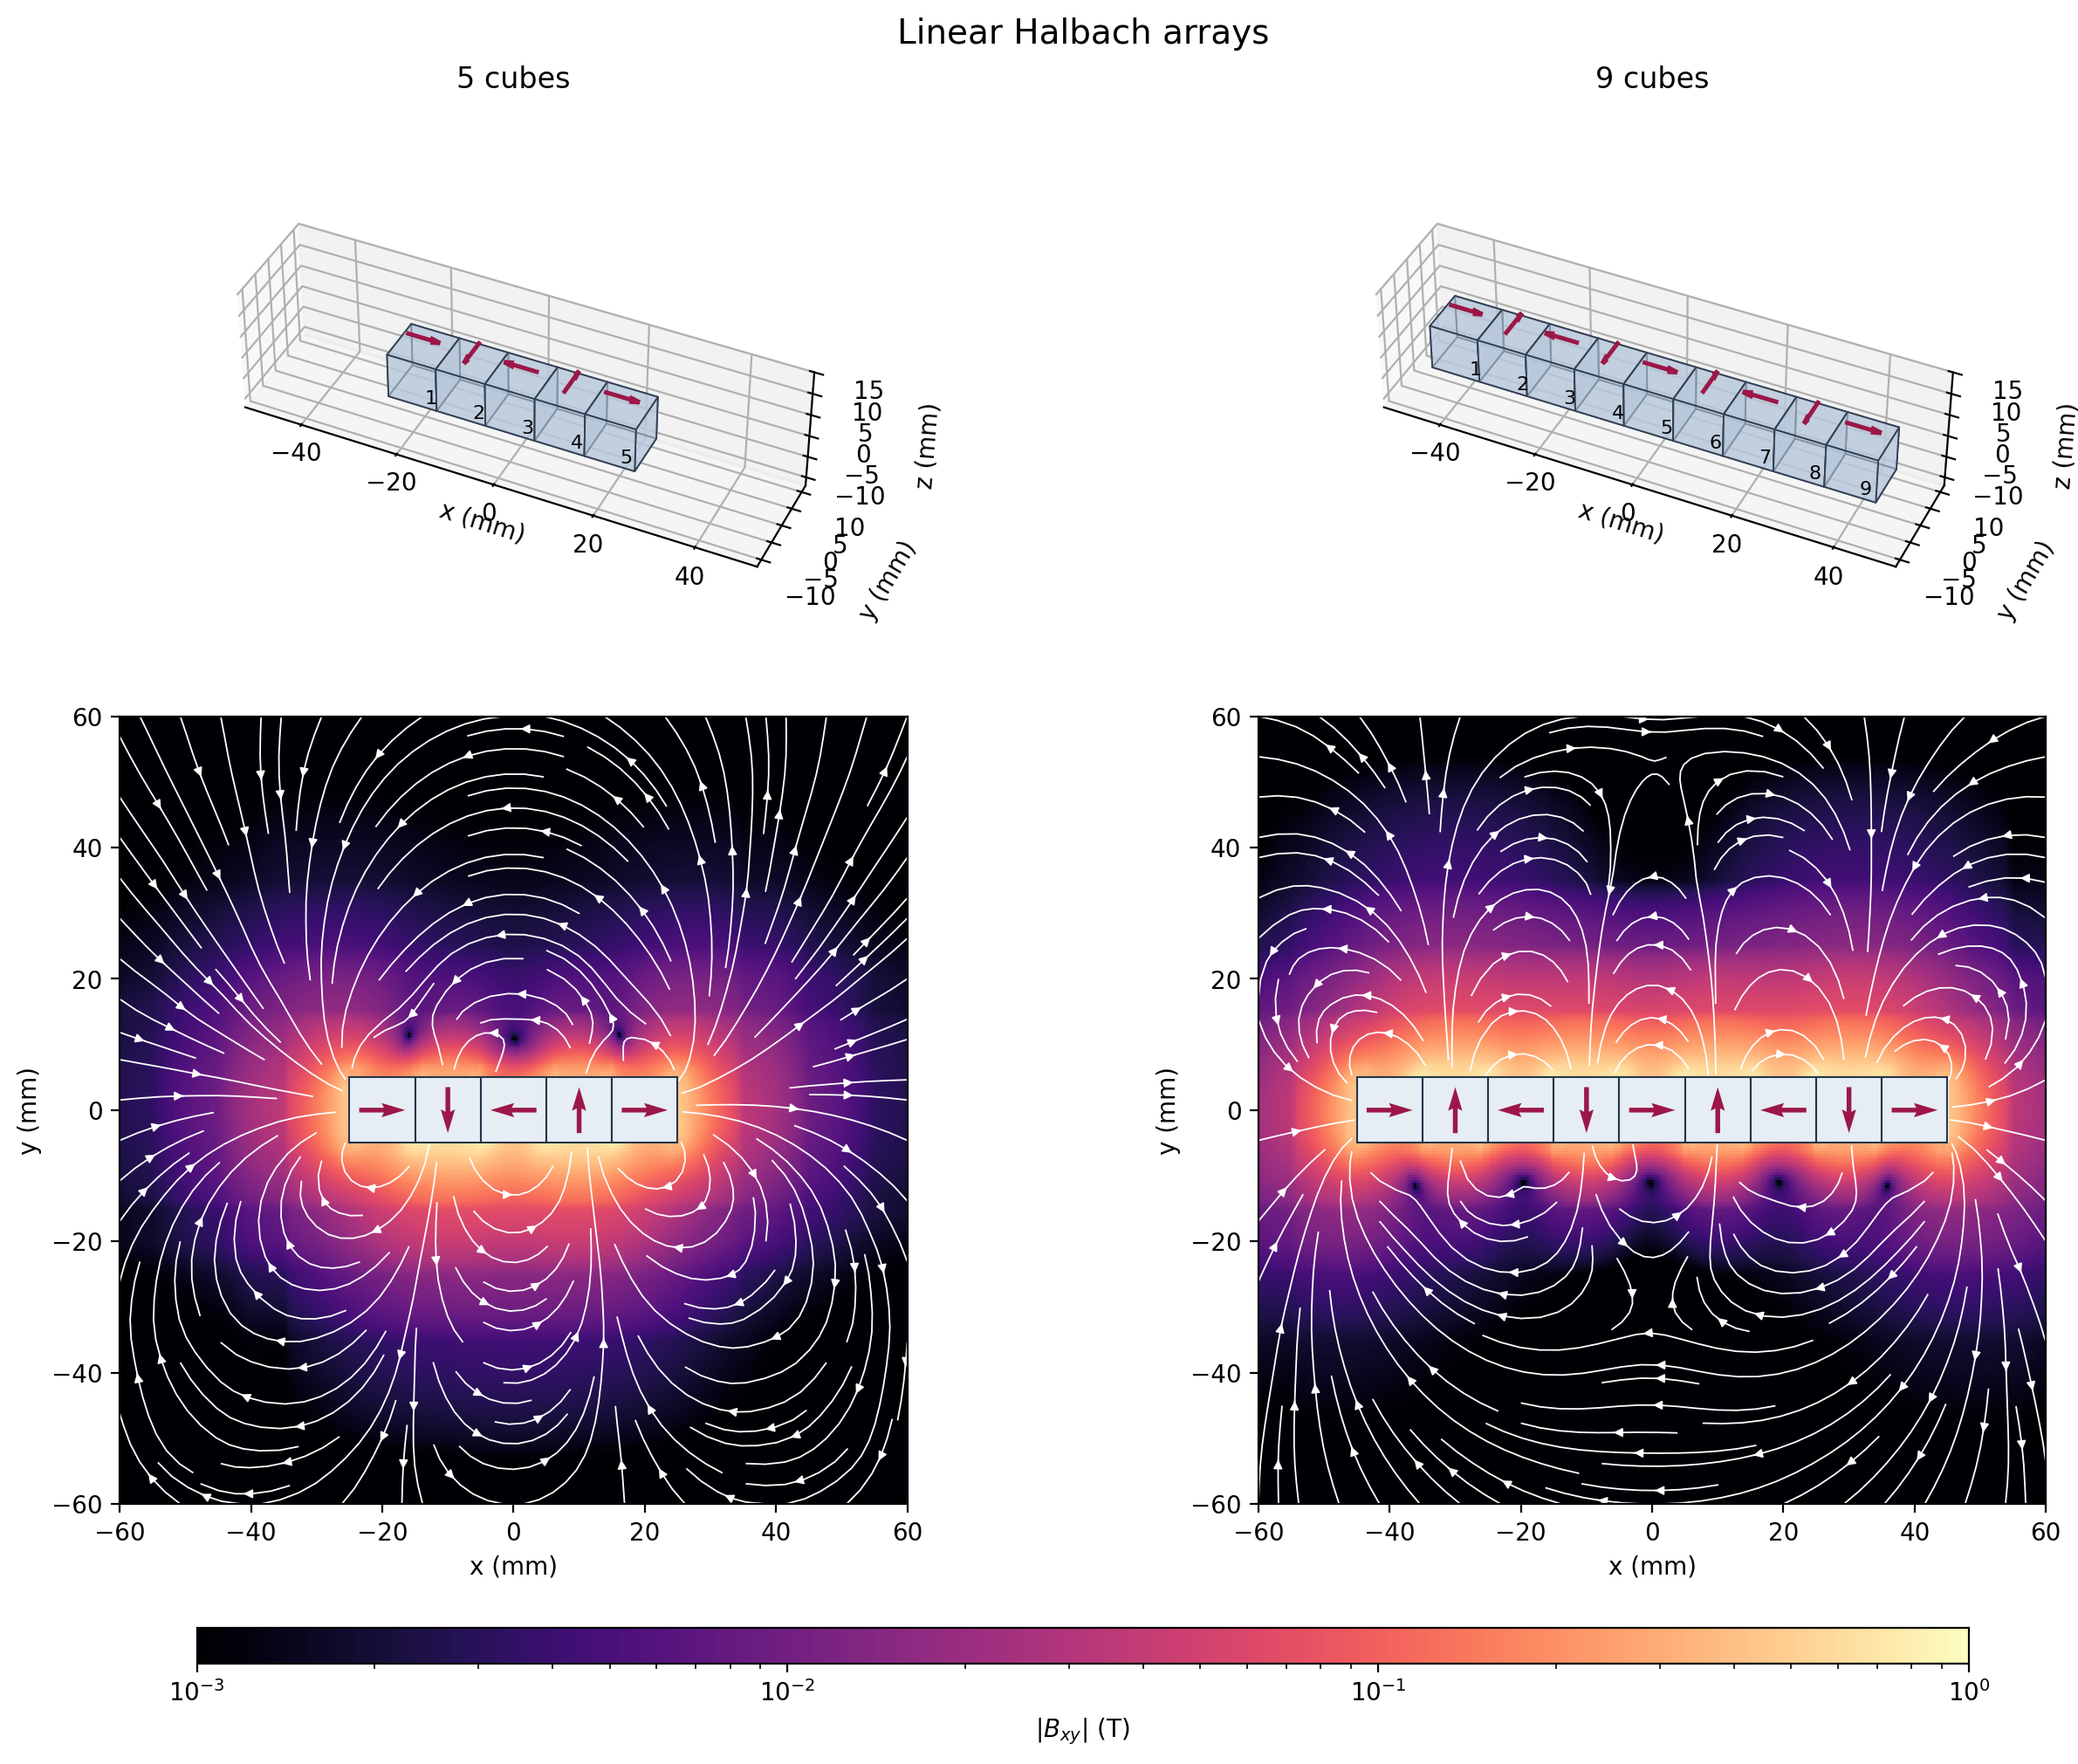

In [3]:
"""This script solves and plots linear Halbach arrays of five and nine cubes."""

import gc
import time

import matplotlib.pyplot as plt
import numpy as np
import pyamg
import skfem
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from scipy.interpolate import RegularGridInterpolator
from scipy.sparse.linalg import cg
from skfem import Basis, ElementTetP1, MeshTet, asm, condense
from skfem.models.poisson import laplace

plt.rcParams['figure.dpi'] = 200

print(f"scikit-fem {skfem.__version__}; three-dimensional scalar-potential FEM")

# Independent five-cube and nine-cube linear arrays
arrangements = []
for count, rotation in ((5, -1), (9, 1)):
    centers = np.column_stack((
        (np.arange(count) - (count - 1) / 2.0) * 0.010,
        np.zeros(count),
        np.zeros(count),
    ))
    angles = rotation * np.arange(count) * np.pi / 2.0
    arrangements.append((f"{count} cubes", centers, angles))
display_centers = np.vstack([item[1] for item in arrangements]) * 1e3
display_half_width = np.max(np.abs(display_centers[:, 0])) * 1e-3 + 0.020
results = []

# Face-conforming tetrahedral meshes and magnetostatic solves
for title, centers, angles in arrangements:
    start_time = time.perf_counter()
    directions = np.column_stack((
        np.cos(angles), np.sin(angles), np.zeros(len(centers))
    ))
    axes = []
    for coordinate in range(3):
        interfaces = np.unique(np.round(np.concatenate((
            centers[:, coordinate] - 0.005,
            centers[:, coordinate] + 0.005,
            np.array([
                centers[:, coordinate].min() - 0.015,
                0.0,
                centers[:, coordinate].max() + 0.015,
            ]),
        )), 12))
        pieces = []
        for left, right in zip(interfaces[:-1], interfaces[1:]):
            pieces.append(np.linspace(
                left, right, int(np.ceil((right - left) / 0.00125)) + 1
            ))
        axes.append(np.unique(np.concatenate((
            interfaces[0] - np.array([0.160, 0.080, 0.040, 0.020, 0.010, 0.005]),
            *pieces,
            interfaces[-1] + np.array([0.005, 0.010, 0.020, 0.040, 0.080, 0.160]),
        ))))

    mesh = MeshTet.init_tensor(*axes)
    basis = Basis(mesh, ElementTetP1(), intorder=1)
    centroids = mesh.p[:, mesh.t].mean(axis=1)
    magnet_id = np.full(mesh.nelements, -1, dtype=np.int8)
    remanence = np.zeros((3, mesh.nelements))
    for index, (center, direction) in enumerate(zip(centers, directions)):
        inside = np.all(np.abs(centroids.T - center) < 0.005, axis=1)
        assert not np.any(magnet_id[inside] >= 0), "Cubes overlap."
        magnet_id[inside] = index
        remanence[:, inside] = 1.2 * direction[:, None]

    volumes = basis.dx.sum(axis=1)
    cube_volumes = np.bincount(
        magnet_id[magnet_id >= 0],
        weights=volumes[magnet_id >= 0],
        minlength=len(centers),
    )
    assert np.allclose(cube_volumes, 0.010**3, rtol=1e-9)

    # B = Br - mu_r grad(u), where u = mu_0 phi_m has units T m.
    # Air: mu_r = 1; magnets: isotropic linear recoil mu_r = 1.05.
    stiffness = asm(laplace, basis)
    stiffness += 0.05 * asm(
        laplace, basis.with_elements(np.flatnonzero(magnet_id >= 0))
    )
    rhs = np.zeros(basis.N)
    for local_index, local_basis in enumerate(basis.basis):
        contribution = np.einsum(
            "ie,ieq,eq->e", remanence, local_basis[0].grad, basis.dx
        )
        np.add.at(rhs, basis.element_dofs[local_index], contribution)

    # u = 0 on the remote air-box boundary approximates u -> 0 at infinity.
    reduced, load, potential, free_dofs = condense(
        stiffness, rhs, D=basis.get_dofs().all()
    )
    hierarchy = pyamg.smoothed_aggregation_solver(reduced, symmetry="symmetric")
    interior_potential, info = cg(
        reduced, load, M=hierarchy.aspreconditioner(), rtol=1e-9, maxiter=600
    )
    if info != 0:
        raise RuntimeError(f"Conjugate-gradient solver returned {info}.")
    potential[free_dofs] = interior_potential
    relative_residual = np.linalg.norm(reduced @ interior_potential - load)
    relative_residual /= np.linalg.norm(load)
    assert relative_residual < 2e-9
    relative_permeability = 1.0 + 0.05 * (magnet_id >= 0)
    field_elements = remanence - relative_permeability[None, :] * (
        basis.interpolate(potential).grad[:, :, 0]
    )

    # Volume-weighted air-side nodal recovery smooths the display only.
    # Magnet interiors are masked; the field solve uses the original FEM field.
    air_elements = magnet_id < 0
    nodal_weight = np.zeros(basis.N)
    nodal_field = np.zeros((basis.N, 3))
    for local_nodes in mesh.t:
        np.add.at(nodal_weight, local_nodes[air_elements], volumes[air_elements])
        np.add.at(
            nodal_field,
            local_nodes[air_elements],
            field_elements[:, air_elements].T * volumes[air_elements, None],
        )
    np.divide(
        nodal_field,
        nodal_weight[:, None],
        out=nodal_field,
        where=nodal_weight[:, None] > 0,
    )
    tensor_field = np.zeros(tuple(len(axis) for axis in axes) + (3,))
    tensor_indices = tuple(
        np.searchsorted(axis, mesh.p[i]) for i, axis in enumerate(axes)
    )
    tensor_field[tensor_indices] = nodal_field
    interpolator = RegularGridInterpolator(tuple(axes), tensor_field)
    extent_x = display_half_width
    extent_y = extent_x
    plot_x = np.linspace(-extent_x, extent_x, 401)
    plot_y = np.linspace(-extent_y, extent_y, 301)
    xx, yy = np.meshgrid(plot_x, plot_y)
    plane = interpolator(np.column_stack((
        xx.ravel(), yy.ravel(), np.zeros(xx.size)
    ))).reshape(xx.shape + (3,))
    solid = np.zeros(xx.shape, dtype=bool)
    for center in centers:
        solid |= (np.abs(xx - center[0]) <= 0.005) & (
            np.abs(yy - center[1]) <= 0.005
        )
    bx = np.ma.array(plane[:, :, 0], mask=solid)
    by = np.ma.array(plane[:, :, 1], mask=solid)
    magnitude = np.ma.sqrt(bx**2 + by**2)

    probe_x = np.linspace(-0.015, 0.015, 201)
    probe_upper = interpolator(np.column_stack((
        probe_x, np.full(probe_x.size, 0.010), np.zeros(probe_x.size)
    )))
    probe_lower = interpolator(np.column_stack((
        probe_x, np.full(probe_x.size, -0.010), np.zeros(probe_x.size)
    )))
    upper_mean = np.linalg.norm(probe_upper, axis=1).mean()
    lower_mean = np.linalg.norm(probe_lower, axis=1).mean()
    diagnostic = (
        f"Mean |B| at y = +10 / -10 mm: "
        f"{upper_mean:.3f} / {lower_mean:.3f} T"
    )

    print(
        f"{title}: {basis.N:,} nodes, {mesh.nelements:,} tetrahedra; "
        f"relative residual {relative_residual:.2e}; "
        f"{time.perf_counter() - start_time:.1f} s\n  {diagnostic}",
        flush=True,
    )
    results.append({
        "title": title,
        "centers": centers,
        "directions": directions,
        "x": plot_x * 1e3,
        "y": plot_y * 1e3,
        "bx": bx,
        "by": by,
        "magnitude": magnitude,
        "diagnostic": diagnostic,
        "residual": relative_residual,
        "upper_mean": upper_mean,
        "lower_mean": lower_mean,
    })
    del basis, mesh, stiffness, reduced, hierarchy, remanence
    del field_elements, tensor_field, nodal_field, interpolator
    gc.collect()

# Cube geometry, magnetization arrows, and field lines
fig = plt.figure(figsize=(13, 10), layout="constrained", dpi=200)
grid = fig.add_gridspec(2, 2, height_ratios=(0.85, 1.15))
field_axes = []
corners = np.array([
    [-1, -1, -1], [1, -1, -1], [1, 1, -1], [-1, 1, -1],
    [-1, -1, 1], [1, -1, 1], [1, 1, 1], [-1, 1, 1],
]) * 5.0
faces = np.array([
    [0, 1, 2, 3], [4, 5, 6, 7], [0, 1, 5, 4],
    [1, 2, 6, 5], [2, 3, 7, 6], [3, 0, 4, 7],
])
norm = LogNorm(vmin=0.001, vmax=1.0)
for column, result in enumerate(results):
    ax3d = fig.add_subplot(
        grid[0, column], projection="3d", computed_zorder=False
    )
    centers_mm = result["centers"] * 1e3
    for index, (center, direction) in enumerate(zip(
        centers_mm, result["directions"]
    )):
        vertices = corners + center
        ax3d.add_collection3d(Poly3DCollection(
            vertices[faces],
            facecolor="#b8c9db",
            edgecolor="#334155",
            linewidth=0.65,
            alpha=0.60,
            zorder=1,
        ))
        ax3d.quiver(
            center[0], center[1], 7.0, *direction, length=7,
            normalize=True, pivot="middle", color="#9c1748",
            linewidth=1.8, arrow_length_ratio=0.30, zorder=10,
        )
        ax3d.text(center[0], center[1], -9.0, str(index + 1), fontsize=8)
    for coordinate, setter in enumerate((ax3d.set_xlim, ax3d.set_ylim)):
        setter(
            display_centers[:, coordinate].min() - 12,
            display_centers[:, coordinate].max() + 12,
        )
    ax3d.set_zlim(-12, 15)
    spans = np.ptp(display_centers, axis=0) + np.array([24, 24, 27])
    ax3d.set_box_aspect(spans)
    ax3d.view_init(elev=40, azim=-65)
    ax3d.set(xlabel="x (mm)", ylabel="y (mm)", zlabel="z (mm)")
    ax3d.set_title(result["title"], pad=8)

    ax = fig.add_subplot(grid[1, column])
    field_axes.append(ax)
    image = ax.pcolormesh(
        result["x"], result["y"], result["magnitude"],
        cmap="magma", norm=norm, shading="auto", rasterized=True,
    )
    ax.streamplot(
        result["x"], result["y"], result["bx"], result["by"],
        color="white", density=1.35, linewidth=0.65, arrowsize=0.75,
    )
    for index, (center, direction) in enumerate(zip(
        centers_mm, result["directions"]
    )):
        ax.add_patch(Rectangle(
            center[:2] - 5, 10, 10, facecolor="#e6edf4",
            edgecolor="#23354a", linewidth=0.75, zorder=5,
        ))
        ax.quiver(
            center[0], center[1], direction[0] * 7, direction[1] * 7,
            angles="xy", scale_units="xy", scale=1, color="#9c1748",
            width=0.006, pivot="mid", zorder=6,
        )
    ax.set(
        xlabel="x (mm)", ylabel="y (mm)",
        aspect="equal", xlim=(result["x"][0], result["x"][-1]),
        ylim=(result["y"][0], result["y"][-1]),
    )

colorbar = fig.colorbar(
    image, ax=field_axes, orientation="horizontal", pad=0.06,
    fraction=0.045, shrink=0.9, aspect=50,
)
colorbar.set_label(r"$|B_{xy}|$ (T)")
fig.suptitle("Linear Halbach arrays", fontsize=14, weight="normal")
plt.show()